# Bisaya Post-Class Speech Affect Recognition (Audio Only)
**Group 1 - First-Year CS students - pilot (n = 30)**

Pipeline: metadata -> validation -> exploratory analysis (RQ1, RQ2) -> audio quality check -> acoustic features + spectrogram embeddings -> RQ3 descriptives -> participant-independent models (RQ4, RQ5) -> accuracy confidence interval and binomial test -> permutation test -> lexically controlled analysis -> prototype.

**Design rules**
- The reference label is always the participant's **self-reported** valence/arousal, never a model's or researcher's reading of the voice.
- Evaluation is leave-one-participant-out, so no participant appears in both training and testing.
- Spoken word, year level, activity, and session are NOT predictors.
- Only speech is analysed. No video or facial data is collected, loaded, or stored.

## Protocol compliance and scope (read before running)
This notebook follows the CS412 Research Mini-Project sheet.

1. **Input = speech only (Sections XIV-XVI).** Acoustic and prosodic features, plus spectrogram embeddings, are the only predictors. The reference is self-reported affect.
2. **Identity must not appear in the dataset or report (Section VI).** Files are named by anonymous participant code only.
3. **Minimum 40 valid observations (Section XVIII).** The validation cell reports whether you reached it.
4. **Spoken word, year level, activity, and session are never predictors (Section XV).** They are used only for description and for the lexically controlled analysis.
5. **Participant-independent evaluation (Section XVI)**: leave-one-participant-out.
6. **Session boundary** (Morning vs Afternoon-Evening) must have been defined before collection; record it in the config cell.
7. **Model selection is done on the same data used for evaluation.** Six audio configurations are compared (2 feature sets x 3 models); the best one is therefore optimistic. Say this in the limitations.

In [2]:
%pip install librosa scikit-learn scipy matplotlib pillow torch torchvision seaborn pandas numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import math
import re
import warnings
from pathlib import Path

import librosa
import librosa.display
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torchvision.models as models
import torchvision.transforms as T
from IPython.display import display
from PIL import Image
from scipy.stats import binomtest, mannwhitneyu
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42
np.random.seed(SEED)

## 1. Configuration

In [4]:
AUDIO_DIR = Path("audio")
METADATA_CSV = Path("GROUP 1_Metadata.csv")

# Every output goes under one folder. (Earlier versions mixed "RESULTS" and "Results",
# which are two different folders on Linux/Colab.)
OUT_DIR = Path("RESULTSV3")
IMG_DIR = OUT_DIR / "SPECTROGRAMS"                     # plain images, the CNN input (no axes)
LABELLED_DIR = OUT_DIR / "spectrograms_labelled"       # images with axes, for the report only
DATA_DIR = OUT_DIR / "datasets"
for d in [OUT_DIR, IMG_DIR, LABELLED_DIR, DATA_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# ---- audio ----
SR = 16000
CLIP_SEC = 1.5
N_MELS = 128
IMG_SIZE = 224

# ---- modelling ----
N_PCA = 5                # PCA components per feature set (keep small for n = 30)
N_PERM = 1000            # permutation-test shuffles (the report used 100; 1000 gives a stable p-value)

# ---- protocol requirements (project sheet) ----
MIN_VALID = 40                 # Section XVIII: minimum valid observations per group
ASSIGNED_YEAR = "1st Year"     # Group 1 is assigned first-year CS students
PROTOCOL_WORDS = ["Salamat", "Ambot", "Grabe", "Lisod", "Sayon", "Lingaw", "Kapoy", "Libog"]
# Session boundary (Morning vs Afternoon-Evening) must be defined BEFORE data collection
# and used by all groups. Write the agreed boundary here for your report:
SESSION_BOUNDARY_NOTE = "e.g. Morning = classes ending before 12:00 PM; Afternoon-Evening = 12:00 PM onward"

# metadata column names (edit if yours differ)
COL_FILE = "Audio Filename"
COL_VAL = "Valence"
COL_ARO = "Arousal"

VAL_THRESHOLD = 3   # valence 4-5 = positive
ARO_THRESHOLD = 3   # arousal 4-5 = high


def save_fig(fig, name):
    path = OUT_DIR / f"{name}.png"
    fig.savefig(path, dpi=300, bbox_inches="tight")   # always save BEFORE plt.show()
    print("saved:", path)

## 2. Load metadata and create labels

In [5]:
raw_meta = pd.read_csv(METADATA_CSV)
df = raw_meta.rename(columns={COL_FILE: "file", COL_VAL: "valence", COL_ARO: "arousal"}).copy()
stem = df["file"].str.replace(".wav", "", regex=False)
parts = stem.str.split("_")
df["participant"] = parts.str[0]
df["word"] = parts.str[-1]
df["path"] = df["file"].apply(lambda f: str(AUDIO_DIR / f))
df["valence_class"] = np.where(df["valence"] > VAL_THRESHOLD, "positive", "non-positive")
df["arousal_class"] = np.where(df["arousal"] > ARO_THRESHOLD, "high", "low-mod")

print("Missing audio:", [p for p in df["path"] if not Path(p).exists()])
df = df[df["path"].apply(lambda p: Path(p).exists())].reset_index(drop=True)
raw_idx = raw_meta.rename(columns={COL_FILE: "file"}).set_index("file")   # metadata looked up by filename

print(len(df), "recordings |", df["participant"].nunique(), "participants")
print(df["valence_class"].value_counts(), "\n")
print(df["arousal_class"].value_counts(), "\n")
print(df["word"].value_counts())

Missing audio: []
30 recordings | 30 participants
valence_class
non-positive    18
positive        12
Name: count, dtype: int64 

arousal_class
low-mod    20
high       10
Name: count, dtype: int64 

word
Kapoy      13
Sayon       3
Lisod       3
Lingaw      3
Salamat     3
Grabe       3
Libog       2
Name: count, dtype: int64


### 2b. Metadata validation (Sections XI and XII)
Checks coded metadata and file naming against the sheet: filename pattern `ParticipantCode_YearLevel_Session_Word.wav`, the seven protocol words, allowed activities, 1-5 ratings, year and session consistency, duplicate participants, and the 40-observation minimum. A word outside the protocol list (for example "Libog") is reported as an issue, not silently accepted.

In [6]:
ACTIVITIES = ["Lecture/Discussion", "Laboratory Activity", "Programming/Coding Activity", "Quiz", "Examination",
              "Presentation/Reporting", "Group Activity", "Recitation", "Project/Practical Activity", "Other"]
YEAR_MAP = {"Y1": "1st Year", "Y2": "2nd Year", "Y3": "3rd Year", "Y4": "4th Year"}
SESSION_MAP = {"AM": "Morning", "PM": "Afternoon-Evening"}
NAME_RE = re.compile(r"^(Y[1-4])-(\d{3})_(Y[1-4])_(AM|PM)_([A-Za-z]+)\.wav$")

issues = []
for _, r in df.iterrows():
    f = r["file"]
    m = NAME_RE.match(f)
    if not m:
        issues.append((f, "filename does not follow ParticipantCode_YearLevel_Session_Word.wav"))
        continue
    code_year, _, name_year, ses, word = m.groups()
    if word not in PROTOCOL_WORDS:
        issues.append((f, f"word '{word}' is not one of the protocol words {PROTOCOL_WORDS}"))
    if code_year != name_year:
        issues.append((f, "year in participant code and in filename differ"))
    if YEAR_MAP[name_year] != ASSIGNED_YEAR:
        issues.append((f, f"year is {YEAR_MAP[name_year]}, group is assigned {ASSIGNED_YEAR}"))
    row = raw_idx.loc[f]
    if "Year Level" in raw_idx.columns and row["Year Level"] != YEAR_MAP[name_year]:
        issues.append((f, "Year Level column does not match filename"))
    if "Session" in raw_idx.columns and row["Session"] != SESSION_MAP[ses]:
        issues.append((f, "Session column does not match AM/PM in filename"))
    if "Spoken Word" in raw_idx.columns and row["Spoken Word"] != word:
        issues.append((f, "Spoken Word column does not match filename"))
    if "Class Activity" in raw_idx.columns and row["Class Activity"] not in ACTIVITIES:
        issues.append((f, f"Class Activity '{row['Class Activity']}' is not an allowed category"))
    for col in ["valence", "arousal"]:
        v = r[col]
        if pd.isna(v) or v not in [1, 2, 3, 4, 5]:
            issues.append((f, f"{col} must be a whole number 1-5 (found {v})"))

dups = df["participant"][df["participant"].duplicated()].unique().tolist()
if dups:
    issues.append(("(multiple)", f"participants with more than one recording: {dups} "
                                 "(allowed only if your approved design permits repeated observations)"))

# gaps in the participant numbering (e.g. Y1-003 missing) - explain these in the report
nums = sorted(int(p.split("-")[1]) for p in df["participant"] if re.match(r"^Y[1-4]-\d{3}$", p))
gaps = [n for n in range(1, max(nums) + 1) if n not in nums] if nums else []

print(f"Valid-looking observations: {len(df)} (required minimum: {MIN_VALID})")
if len(df) < MIN_VALID:
    print(f"WARNING: {MIN_VALID - len(df)} observations short of the minimum. State this and the reason in your limitations.")
if gaps:
    print("Participant numbers not present:", [f"{n:03d}" for n in gaps])
if issues:
    print(f"\n{len(issues)} issue(s) to fix or explain:")
    issues_df = pd.DataFrame(issues, columns=["file", "issue"])
    display(issues_df)
    issues_df.to_csv(OUT_DIR / "metadata_issues.csv", index=False, encoding="utf-8")
else:
    print("Metadata and filenames follow the protocol.")
print("\nSession boundary used:", SESSION_BOUNDARY_NOTE)

Valid-looking observations: 30 (required minimum: 40)
Participant numbers not present: ['003', '005', '007']
Metadata and filenames follow the protocol.

Session boundary used: e.g. Morning = classes ending before 12:00 PM; Afternoon-Evening = 12:00 PM onward


### DEMO A: Raw data and dataset verification
Participant counts, file correspondence (each metadata row → its WAV and MP4), and valid target labels. Run this live during the demo.

In [7]:
# Paste right after the "2b. Metadata validation" cell. Needs: raw_meta, COL_FILE, COL_VAL, COL_ARO, AUDIO_DIR.
# Shows participant counts, which files match which metadata rows, and whether every target label is valid.
VIDEO_DIR = Path("video")   # facial data (videos); only checked for correspondence, not analysed

meta_files = raw_meta[COL_FILE].astype(str).tolist()
wav_files = sorted(p.name for p in AUDIO_DIR.glob("*.wav"))
mp4_files = sorted(p.name for p in VIDEO_DIR.glob("*.mp4")) if VIDEO_DIR.exists() else []

check = pd.DataFrame({
    "participant": raw_meta["Participant Code"] if "Participant Code" in raw_meta.columns else raw_meta[COL_FILE].str.split("_").str[0],
    "audio_file": meta_files,
    "wav_found": [f in wav_files for f in meta_files],
    "mp4_found": [Path(f).with_suffix(".mp4").name in mp4_files for f in meta_files],
    "valence": raw_meta[COL_VAL].values,
    "arousal": raw_meta[COL_ARO].values,
})
check["labels_valid"] = check["valence"].isin([1, 2, 3, 4, 5]) & check["arousal"].isin([1, 2, 3, 4, 5])
check["valence_class"] = np.where(check["valence"] > VAL_THRESHOLD, "positive", "non-positive")
check["arousal_class"] = np.where(check["arousal"] > ARO_THRESHOLD, "high", "low-mod")

summary = pd.DataFrame({
    "item": ["metadata rows", "unique participants", "WAV files in audio/", "metadata rows with a WAV",
             "MP4 files in video/", "metadata rows with an MP4", "rows with valid 1-5 labels"],
    "count": [len(check), check["participant"].nunique(), len(wav_files), int(check["wav_found"].sum()),
              len(mp4_files), int(check["mp4_found"].sum()), int(check["labels_valid"].sum())],
})
display(summary)

orphan_wav = sorted(set(wav_files) - set(meta_files))
orphan_mp4 = sorted(set(mp4_files) - {Path(f).with_suffix(".mp4").name for f in meta_files})
print("WAV files with no metadata row:", orphan_wav or "none")
print("MP4 files with no metadata row:", orphan_mp4 or "none")

print("\nTarget labels (derived from self-report):")
display(pd.concat({"valence_class": check["valence_class"].value_counts(),
                   "arousal_class": check["arousal_class"].value_counts()}).to_frame("count"))

print("File correspondence, one row per participant:")
display(check)
check.to_csv(OUT_DIR / "file_correspondence_check.csv", index=False)


,item,count
0,metadata rows,30
1,unique participants,30
2,WAV files in audio/,30
3,metadata rows with a WAV,30
4,MP4 files in video/,30
5,metadata rows with an MP4,30
6,rows with valid 1-5 labels,30


WAV files with no metadata row: none
MP4 files with no metadata row: none

Target labels (derived from self-report):


count
valence_class non-positive     18
              positive         12
arousal_class low-mod          20
              high             10

File correspondence, one row per participant:


,participant,audio_file,wav_found,mp4_found,valence,arousal,labels_valid,valence_class,arousal_class
0,Y1-001,Y1-001_Y1_AM_Kapoy.wav,True,True,4,4,True,positive,high
1,Y1-002,Y1-002_Y1_AM_Libog.wav,True,True,3,2,True,non-positive,low-mod
2,Y1-004,Y1-004_Y1_AM_Libog.wav,True,True,4,3,True,positive,low-mod
3,Y1-006,Y1-006_Y1_AM_Sayon.wav,True,True,4,1,True,positive,low-mod
4,Y1-008,Y1-008_Y1_AM_Kapoy.wav,True,True,3,2,True,non-positive,low-mod
5,Y1-009,Y1-009_Y1_AM_Lisod.wav,True,True,3,3,True,non-positive,low-mod
6,Y1-010,Y1-010_Y1_AM_Kapoy.wav,True,True,1,3,True,non-positive,low-mod
7,Y1-011,Y1-011_Y1_AM_Kapoy.wav,True,True,3,4,True,non-positive,high
8,Y1-012,Y1-012_Y1_AM_Kapoy.wav,True,True,4,4,True,positive,high
9,Y1-013,Y1-013_Y1_AM_Lingaw.wav,True,True,4,5,True,positive,high


## 3. Exploratory analysis (Section XIII: context x affect, RQ2)
Done before any modelling, as the project sheet requires. All participants in this group are first-year, so Year Level has a single value; it becomes comparable only after the class datasets are pooled. Descriptive only: no statistical tests are run here.

,valence,arousal
count,30.00,30.00
mean,3.20,2.80
std,0.92,1.24
min,1.00,1.00
25%,3.00,2.00
50%,3.00,3.00
75%,4.00,4.00
max,5.00,5.00


saved: RESULTSV3\exploratory_rating_distribution.png


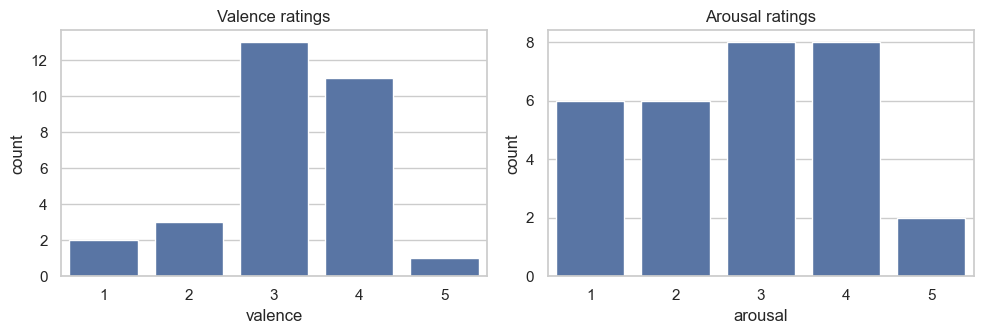


=== Year Level x affect ===


valence            arousal           
             count mean   std   count mean   std
Year Level                                      
1st Year        30  3.2  0.92      30  2.8  1.24

Only one Year Level value in this group, so no comparison is possible yet.

=== Class Activity x affect ===


valence             arousal            
                             count  mean   std   count  mean   std
Class Activity                                                    
Examination                      9  3.22  1.20       9  2.33  1.00
Laboratory Activity              1  2.00   NaN       1  1.00   NaN
Lecture/Discussion               4  2.75  0.50       4  3.00  0.82
Presentation/Reporting           2  4.00  0.00       2  5.00  0.00
Project/Practical Activity       3  3.67  0.58       3  4.00  0.00
Quiz                            11  3.18  0.87      11  2.55  1.21

saved: RESULTSV3\exploratory_class_activity.png


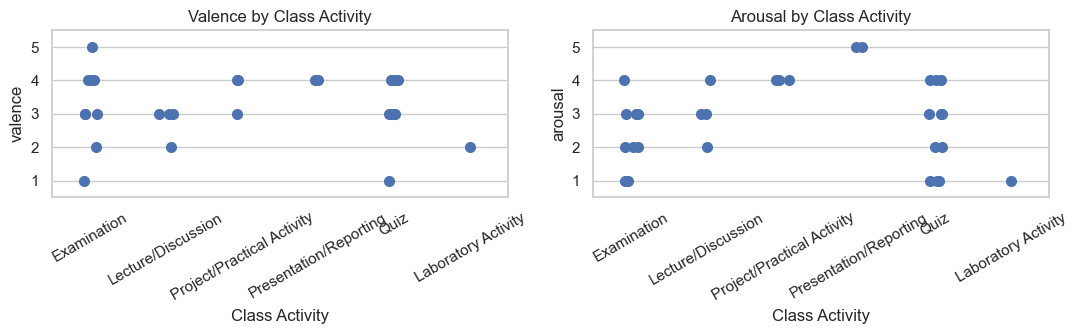


=== Session x affect ===


valence             arousal            
                    count  mean   std   count  mean   std
Session                                                  
Afternoon-Evening      17  3.06  0.97      17  2.41  1.18
Morning                13  3.38  0.87      13  3.31  1.18

saved: RESULTSV3\exploratory_session.png


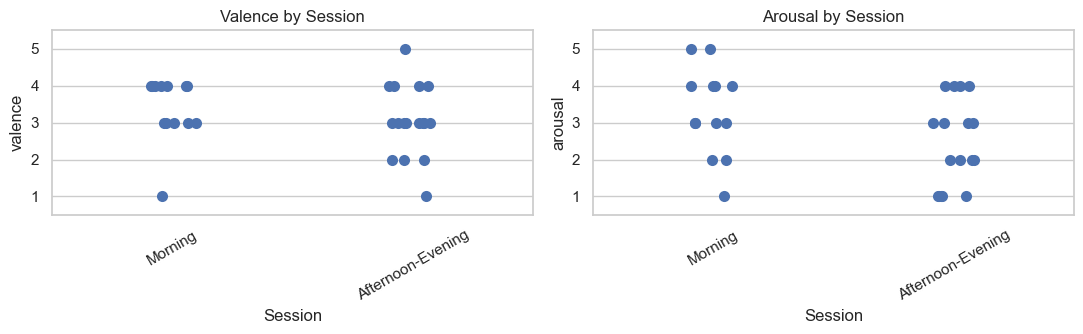


=== word x affect ===


valence             arousal            
          count  mean   std   count  mean   std
word                                           
Grabe         3  3.00  1.00       3  2.67  1.53
Kapoy        13  2.92  1.04      13  2.77  1.09
Libog         2  3.50  0.71       2  2.50  0.71
Lingaw        3  4.33  0.58       3  3.67  1.53
Lisod         3  2.67  0.58       3  2.33  1.15
Salamat       3  3.67  0.58       3  3.67  1.53
Sayon         3  3.33  0.58       3  2.00  1.73

saved: RESULTSV3\exploratory_word.png


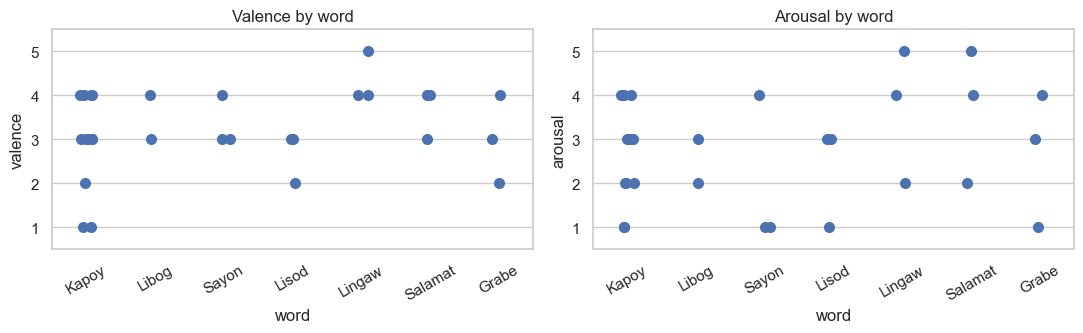


=== Spoken word x Class Activity (counts) ===


word,Grabe,Kapoy,Libog,Lingaw,Lisod,Salamat,Sayon
Class Activity,,,,,,,
Examination,0,3,2,1,2,0,1
Laboratory Activity,1,0,0,0,0,0,0
Lecture/Discussion,1,3,0,0,0,0,0
Presentation/Reporting,0,0,0,1,0,1,0
Project/Practical Activity,0,2,0,1,0,0,0
Quiz,1,5,0,0,1,2,2


In [8]:
CONTEXT_COLS = ["Year Level", "Class Activity", "Session"]
for c in CONTEXT_COLS:
    if c in raw_idx.columns:
        df[c] = df["file"].map(raw_idx[c])

desc = df[["valence", "arousal"]].describe().round(2)
display(desc)
desc.to_csv(OUT_DIR / "exploratory_rating_summary.csv")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
sns.countplot(x="valence", data=df, order=[1, 2, 3, 4, 5], ax=axes[0]); axes[0].set_title("Valence ratings")
sns.countplot(x="arousal", data=df, order=[1, 2, 3, 4, 5], ax=axes[1]); axes[1].set_title("Arousal ratings")
plt.tight_layout()
save_fig(fig, "exploratory_rating_distribution")
plt.show()

for c in CONTEXT_COLS + ["word"]:
    if c not in df.columns:
        continue
    slug = c.lower().replace(" ", "_")
    print(f"\n=== {c} x affect ===")
    tbl = df.groupby(c)[["valence", "arousal"]].agg(["count", "mean", "std"]).round(2)
    display(tbl)
    tbl.to_csv(OUT_DIR / f"exploratory_{slug}_summary.csv")
    if df[c].nunique() < 2:
        print(f"Only one {c} value in this group, so no comparison is possible yet.")
        continue
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    for ax, v in zip(axes, ["valence", "arousal"]):
        sns.stripplot(data=df, x=c, y=v, ax=ax, jitter=True, size=8)
        ax.set_ylim(0.5, 5.5); ax.set_title(f"{v.capitalize()} by {c}"); ax.tick_params(axis="x", rotation=30)
    plt.tight_layout()
    save_fig(fig, f"exploratory_{slug}")
    plt.show()

if "Class Activity" in df.columns:
    print("\n=== Spoken word x Class Activity (counts) ===")
    ct = pd.crosstab(df["Class Activity"], df["word"])
    display(ct)
    ct.to_csv(OUT_DIR / "exploratory_word_by_activity_counts.csv")

### RQ1: reported affective states
Counts of the participants' own words for how they feel (free text), and where they fall on the valence-arousal grid.

Self-reported feelings (free text):


,count
feeling,
kapoy,12
lingaw,2
grabe,2
lisod,2
libog,1
nagmahay ko kay wala nako nakita ang bonus,1
okay lang,1
galisod,1
gikapoy,1


Valence class x arousal class (counts):


arousal_class,high,low-mod
valence_class,,
non-positive,3,15
positive,7,5


saved: RESULTSV3\rq1_valence_arousal_scatter.png


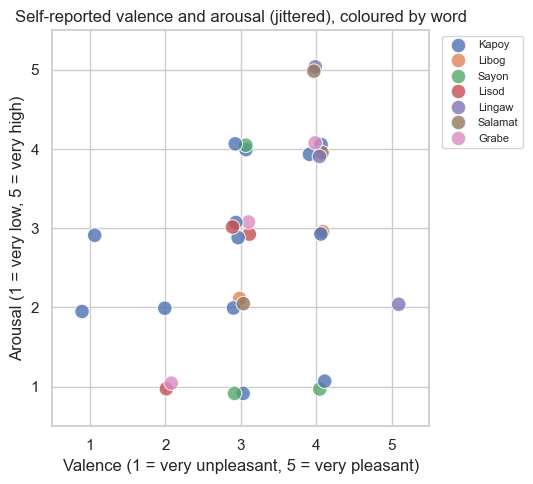

saved: RESULTSV3\rq1_valence_arousal_counts.png


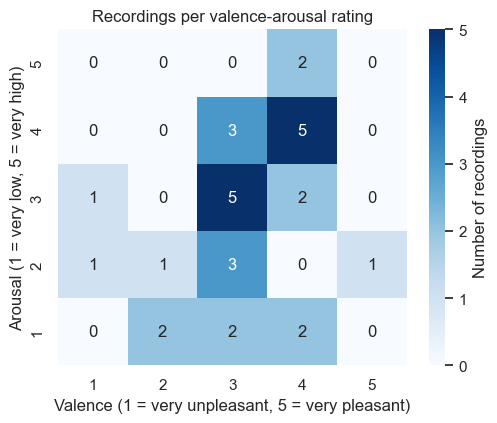

In [9]:
# ---- free-text feelings ----
if "Self-Reported Feeling" in raw_idx.columns:
    df["feeling"] = df["file"].map(raw_idx["Self-Reported Feeling"]).astype(str).str.strip().str.lower()
    print("Self-reported feelings (free text):")
    feelings = df["feeling"].value_counts().to_frame("count")
    display(feelings)
    feelings.to_csv(OUT_DIR / "rq1_self_reported_feelings_counts.csv", encoding="utf-8")

# ---- valence class x arousal class counts ----
print("Valence class x arousal class (counts):")
class_counts = pd.crosstab(df["valence_class"], df["arousal_class"])
display(class_counts)
class_counts.to_csv(OUT_DIR / "rq1_valence_class_by_arousal_class_counts.csv", encoding="utf-8")

# ---- scatter of ratings (jittered, so overlapping points stay visible) ----
rng_j = np.random.default_rng(SEED)
fig = plt.figure(figsize=(5.5, 5))
sns.scatterplot(x=df["valence"] + rng_j.uniform(-0.12, 0.12, len(df)),
                y=df["arousal"] + rng_j.uniform(-0.12, 0.12, len(df)),
                hue=df["word"], s=110, alpha=0.8)
plt.xlim(0.5, 5.5); plt.ylim(0.5, 5.5)
plt.xlabel("Valence (1 = very unpleasant, 5 = very pleasant)")
plt.ylabel("Arousal (1 = very low, 5 = very high)")
plt.title("Self-reported valence and arousal (jittered), coloured by word")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
save_fig(fig, "rq1_valence_arousal_scatter")
plt.show()

# ---- exact counts for every valence x arousal rating combination ----
grid = (pd.crosstab(df["arousal"], df["valence"])
          .reindex(index=[1, 2, 3, 4, 5], columns=[1, 2, 3, 4, 5], fill_value=0))
grid.to_csv(OUT_DIR / "rq1_valence_by_arousal_rating_counts.csv", encoding="utf-8")

fig2 = plt.figure(figsize=(5.2, 4.4))
sns.heatmap(grid.sort_index(ascending=False), annot=True, fmt="d", cmap="Blues",
            cbar_kws={"label": "Number of recordings"})
plt.xlabel("Valence (1 = very unpleasant, 5 = very pleasant)")
plt.ylabel("Arousal (1 = very low, 5 = very high)")
plt.title("Recordings per valence-arousal rating")
plt.tight_layout()
save_fig(fig2, "rq1_valence_arousal_counts")
plt.show()

## 4. Audio data quality report (deliverable 5)
Checks each original WAV for sample rate, channels, length, level, clipping, and silence before any processing. Review flagged files and decide whether they are valid recordings.

In [10]:
qa_rows = []
for i, r in df.iterrows():
    y0, sr0 = librosa.load(r["path"], sr=None, mono=False)
    n_ch = 1 if y0.ndim == 1 else y0.shape[0]
    y1 = y0 if y0.ndim == 1 else y0.mean(axis=0)
    dur = len(y1) / sr0
    peak = float(np.max(np.abs(y1)))
    clip = float(np.mean(np.abs(y1) >= 0.99))
    rms_db = float(20 * np.log10(np.sqrt(np.mean(y1 ** 2)) + 1e-9))
    segs = librosa.effects.split(y1, top_db=30)
    active = float(sum(e - s for s, e in segs) / len(y1)) if len(y1) else 0.0
    flags = []
    if dur < 0.3: flags.append("very short")
    if dur > 5: flags.append("long (may contain extra speech)")
    if peak < 0.05: flags.append("very quiet")
    if clip > 0.001: flags.append("clipping")
    if active < 0.1: flags.append("mostly silence")
    qa_rows.append({"file": r["file"], "sample_rate": sr0, "channels": n_ch, "duration_s": round(dur, 2),
                    "peak": round(peak, 3), "rms_dB": round(rms_db, 1), "clipping_frac": round(clip, 4),
                    "active_ratio": round(active, 2), "flags": "; ".join(flags)})
qa_audio = pd.DataFrame(qa_rows)
qa_audio.to_csv(OUT_DIR / "audio_quality_report.csv", index=False)
print("Sample rates present:", sorted(qa_audio["sample_rate"].unique()))
print("Channel counts present:", sorted(qa_audio["channels"].unique()))
display(qa_audio.describe().round(2))
flagged = qa_audio[qa_audio["flags"] != ""]
print(f"Flagged recordings: {len(flagged)}")
display(flagged)

Sample rates present: [np.int64(192000)]
Channel counts present: [np.int64(2)]


,sample_rate,channels,duration_s,peak,rms_dB,clipping_frac,active_ratio
count,30.0,30.0,30.00,30.00,30.00,30.0,30.00
mean,192000.0,2.0,1.24,0.29,-29.37,0.0,0.67
std,0.0,0.0,0.31,0.06,1.24,0.0,0.23
min,192000.0,2.0,0.68,0.19,-31.60,0.0,0.21
25%,192000.0,2.0,0.98,0.25,-30.00,0.0,0.46
50%,192000.0,2.0,1.18,0.27,-29.65,0.0,0.68
75%,192000.0,2.0,1.46,0.33,-28.45,0.0,0.90
max,192000.0,2.0,2.01,0.41,-26.90,0.0,0.99


Flagged recordings: 0


,file,sample_rate,channels,duration_s,peak,rms_dB,clipping_frac,active_ratio,flags


## 5. Acoustic features and spectrograms (Section XIV)
Each recording is resampled to 16 kHz mono, trimmed (25 dB), and peak-normalised. Then:
- **Handcrafted features (67):** duration, segments, active-speech ratio, RMS peak position, pitch (f0) mean/SD/range, voiced ratio, RMS energy, zero-crossing rate, spectral centroid, and MFCCs 1-13 with delta and delta-delta SDs.
- **Plain mel-spectrogram images** (no axes), padded or cut to 1.5 s, used as the CNN input.
- **Labelled spectrograms** (with axes) for the report only.

Note: the right-hand black region in short clips is zero-padding, not silence in the recording. Brightness is relative to each clip's own peak, so it cannot be compared across clips.

In [11]:
def load_audio(path):
    y, _ = librosa.load(path, sr=SR, mono=True)
    y, _ = librosa.effects.trim(y, top_db=25)
    if len(y) < 1024:
        y = np.pad(y, (0, 1024 - len(y)))
    return librosa.util.normalize(y)


def summarize(x, name):
    return {f"{name}_mean": float(np.mean(x)), f"{name}_std": float(np.std(x))}


def handcrafted_features(y):
    f = {"duration": len(y) / SR}
    # temporal / rhythm characteristics (Section XIV)
    segs = librosa.effects.split(y, top_db=30)
    f["n_segments"] = len(segs)
    f["active_ratio"] = float(sum(e - s for s, e in segs) / len(y))
    rms = librosa.feature.rms(y=y)[0]
    f["rms_peak_pos"] = float(np.argmax(rms) / max(len(rms) - 1, 1))
    # pitch
    f0, voiced, _ = librosa.pyin(y, fmin=65, fmax=500, sr=SR)
    f0v = f0[~np.isnan(f0)]
    if len(f0v) > 0:
        f.update({"f0_mean": f0v.mean(), "f0_std": f0v.std(), "f0_range": f0v.max() - f0v.min()})
    else:
        f.update({"f0_mean": 0.0, "f0_std": 0.0, "f0_range": 0.0})
    f["voiced_ratio"] = float(np.mean(voiced))
    # energy and spectrum
    f.update(summarize(rms, "rms")); f["rms_max"] = float(rms.max())
    f.update(summarize(librosa.feature.zero_crossing_rate(y)[0], "zcr"))
    f.update(summarize(librosa.feature.spectral_centroid(y=y, sr=SR)[0], "centroid"))
    # MFCCs
    mfcc = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=13)
    d1 = librosa.feature.delta(mfcc, width=5, mode="nearest")
    d2 = librosa.feature.delta(mfcc, order=2, width=5, mode="nearest")
    for i in range(13):
        f.update(summarize(mfcc[i], f"mfcc{i}"))
        f[f"dmfcc{i}_std"] = float(np.std(d1[i]))
        f[f"ddmfcc{i}_std"] = float(np.std(d2[i]))
    return f


def fixed_length(y):
    n = int(CLIP_SEC * SR)
    return y[:n] if len(y) >= n else np.pad(y, (0, n - len(y)))


def mel_db(y):
    S = librosa.feature.melspectrogram(y=fixed_length(y), sr=SR, n_fft=1024, hop_length=128, n_mels=N_MELS)
    return librosa.power_to_db(S, ref=np.max)


def make_spectrogram(y, out_path):
    # Plain image (no axes) that is fed to the CNN. Do not add axes here.
    S_db = mel_db(y)
    S_norm = (S_db - S_db.min()) / (S_db.max() - S_db.min() + 1e-9)
    rgb = (matplotlib.colormaps["magma"](S_norm)[..., :3] * 255).astype(np.uint8)
    Image.fromarray(np.flipud(rgb)).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR).save(out_path)
    return str(out_path)


def draw_labelled(ax, y, title):
    img = librosa.display.specshow(mel_db(y), sr=SR, hop_length=128, x_axis="time", y_axis="mel",
                                   fmax=SR / 2, cmap="magma", vmin=-80, vmax=0, ax=ax)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Time (s)", fontsize=9)
    ax.set_ylabel("Frequency (Hz)", fontsize=9)
    ax.tick_params(labelsize=8)
    return img


hand_rows, img_paths, audio_cache = [], [], {}
for i, r in df.iterrows():
    y = load_audio(r["path"])
    audio_cache[i] = y
    hand_rows.append(handcrafted_features(y))
    img_paths.append(make_spectrogram(y, IMG_DIR / (Path(r["file"]).stem + ".png")))

hand = pd.DataFrame(hand_rows).fillna(0.0)
X_hand = hand.values
print("Handcrafted audio features:", X_hand.shape)
hand.assign(file=df["file"]).to_csv(OUT_DIR / "acoustic_features.csv", index=False)

Handcrafted audio features: (30, 67)


### DEMO B: One raw recording → structured feature vector
Walks one WAV through resampling, trimming and normalisation, then shows all 67 feature columns with their values, and checks the result matches the saved dataset row. Change `DEMO_FILE` to show a different recording.

Demo recording: Y1-014_Y1_AM_Salamat.wav


,step,sample rate,channels,samples,duration (s),peak
0,1. Raw WAV,192000 Hz,2,184320,0.960,0.251
1,2. Resample to 16 kHz mono,16000 Hz,1,15360,0.960,0.254
2,3. Trim silence (25 dB),16000 Hz,1,14848,0.928,0.254
3,4. Peak-normalise,16000 Hz,1,14848,0.928,1.000


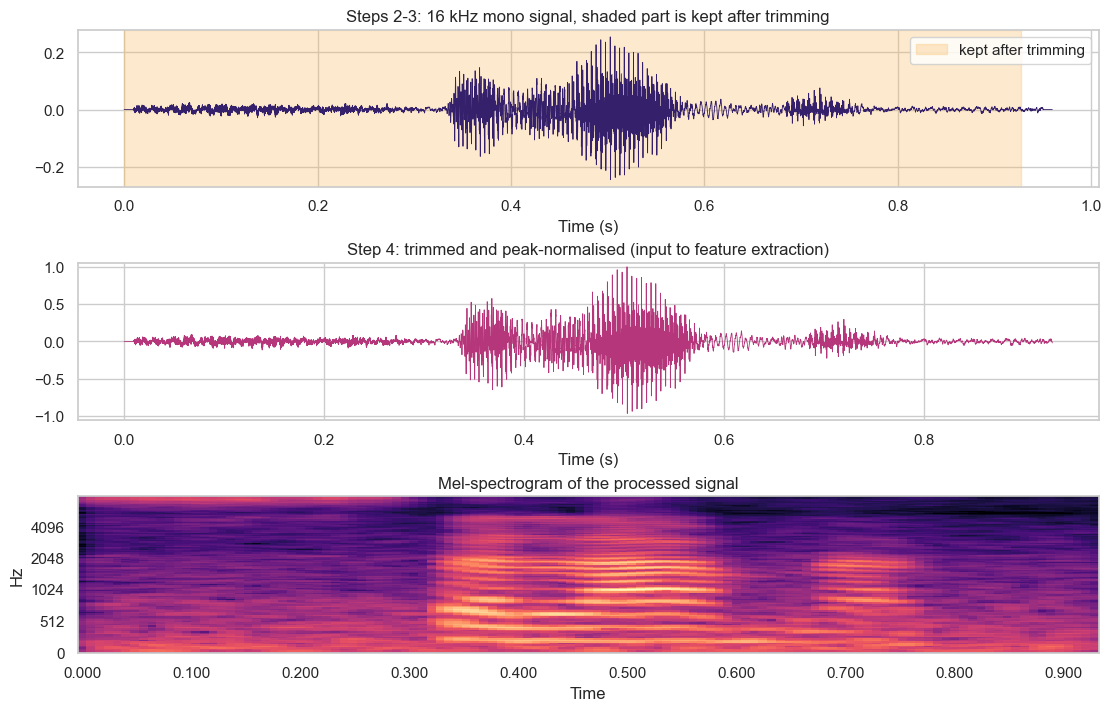

Step 5: 67 features extracted


,number of features
group,
Energy,4
MFCC delta SD,13
MFCC delta-delta SD,13
MFCC mean/SD,26
Pitch,4
Spectral centroid,2
Timing,3
Zero-crossing rate,2


,group,feature,value
0,Timing,duration,0.9280
1,Timing,n_segments,1.0000
2,Timing,active_ratio,1.0000
3,Energy,rms_peak_pos,0.5517
4,Pitch,f0_mean,199.4533
5,Pitch,f0_std,19.6950
6,Pitch,f0_range,68.0644
7,Pitch,voiced_ratio,0.5667
8,Energy,rms_mean,0.0875
9,Energy,rms_std,0.0833


,duration,n_segments,active_ratio,rms_peak_pos,f0_mean,f0_std,f0_range,voiced_ratio,rms_mean,rms_std,...,dmfcc10_std,ddmfcc10_std,mfcc11_mean,mfcc11_std,dmfcc11_std,ddmfcc11_std,mfcc12_mean,mfcc12_std,dmfcc12_std,ddmfcc12_std
0,0.928,1,1.0,0.551724,199.453329,19.69501,68.064412,0.566667,0.087516,0.083317,...,2.093854,2.204211,-4.769782,4.347955,1.089592,1.560316,6.836292,7.221294,2.380368,2.609677


Identical to the row in acoustic_features.csv: True


In [12]:
# [DEMO B] ===================== ONE RECORDING -> FEATURE VECTOR =====================
# Paste right after the "def load_audio(path):" feature-extraction cell. Needs: load_audio steps, handcrafted_features,
# hand, df, SR. Walks one raw WAV through every preprocessing step and shows the resulting 67 feature columns.
import librosa.display

DEMO_FILE = "Y1-014_Y1_AM_Salamat.wav"      # change to any file in audio/
path = AUDIO_DIR / DEMO_FILE

# Step 1: raw file as recorded
y_raw, sr_raw = librosa.load(path, sr=None, mono=False)
n_ch = 1 if y_raw.ndim == 1 else y_raw.shape[0]
y_raw_mono = y_raw if y_raw.ndim == 1 else y_raw.mean(axis=0)
# Step 2: resample to 16 kHz mono (same call as load_audio)
y16, _ = librosa.load(path, sr=SR, mono=True)
# Step 3: trim leading/trailing silence (25 dB below peak)
y_trim, (t0, t1) = librosa.effects.trim(y16, top_db=25)
# Step 4: peak-normalise
y_proc = librosa.util.normalize(y_trim)

steps = pd.DataFrame([
    ["1. Raw WAV", f"{sr_raw} Hz", n_ch, len(y_raw_mono), round(len(y_raw_mono) / sr_raw, 3), round(float(np.abs(y_raw_mono).max()), 3)],
    ["2. Resample to 16 kHz mono", f"{SR} Hz", 1, len(y16), round(len(y16) / SR, 3), round(float(np.abs(y16).max()), 3)],
    ["3. Trim silence (25 dB)", f"{SR} Hz", 1, len(y_trim), round(len(y_trim) / SR, 3), round(float(np.abs(y_trim).max()), 3)],
    ["4. Peak-normalise", f"{SR} Hz", 1, len(y_proc), round(len(y_proc) / SR, 3), round(float(np.abs(y_proc).max()), 3)],
], columns=["step", "sample rate", "channels", "samples", "duration (s)", "peak"])
print(f"Demo recording: {DEMO_FILE}")
display(steps)

fig, axes = plt.subplots(3, 1, figsize=(11, 7), constrained_layout=True)
t = np.arange(len(y16)) / SR
axes[0].plot(t, y16, linewidth=0.6, color="#35206B")
axes[0].axvspan(t0 / SR, t1 / SR, color="#F9B95C", alpha=0.3, label="kept after trimming")
axes[0].set_title("Steps 2-3: 16 kHz mono signal, shaded part is kept after trimming"); axes[0].legend(loc="upper right")
axes[1].plot(np.arange(len(y_proc)) / SR, y_proc, linewidth=0.6, color="#B5367A")
axes[1].set_title("Step 4: trimmed and peak-normalised (input to feature extraction)"); axes[1].set_ylim(-1.05, 1.05)
S_db = librosa.power_to_db(librosa.feature.melspectrogram(y=y_proc, sr=SR, n_fft=1024, hop_length=128, n_mels=N_MELS), ref=np.max)
librosa.display.specshow(S_db, sr=SR, hop_length=128, x_axis="time", y_axis="mel", fmax=SR / 2, cmap="magma", ax=axes[2])
axes[2].set_title("Mel-spectrogram of the processed signal")
for ax in axes[:2]: ax.set_xlabel("Time (s)")
plt.show()

# Step 5: feature vector
vec = handcrafted_features(y_proc)
GROUPS = [("mfcc", "MFCC mean/SD"), ("dmfcc", "MFCC delta SD"), ("ddmfcc", "MFCC delta-delta SD"), ("f0", "Pitch"),
          ("voiced", "Pitch"), ("rms", "Energy"), ("zcr", "Zero-crossing rate"), ("centroid", "Spectral centroid")]
def group_of(name):
    for prefix, g in GROUPS:
        if name.startswith(prefix): return g
    return "Timing"
feat_table = pd.DataFrame({"feature": list(vec.keys()), "value": [round(float(v), 4) for v in vec.values()]})
feat_table["group"] = feat_table["feature"].apply(group_of)
print(f"Step 5: {len(feat_table)} features extracted")
display(feat_table.groupby("group").size().to_frame("number of features"))
pd.set_option("display.max_rows", 100)
display(feat_table[["group", "feature", "value"]])

# Same recording as one structured row of the dataset (1 x 67), and a check that it matches the saved dataset row
row_idx = df.index[df["file"] == DEMO_FILE][0]
vector = pd.DataFrame([vec])[hand.columns]
display(vector)
print("Identical to the row in acoustic_features.csv:", np.allclose(vector.values[0], hand.loc[row_idx].values, equal_nan=True))


saved: RESULTSV3\spectrogram_examples.png


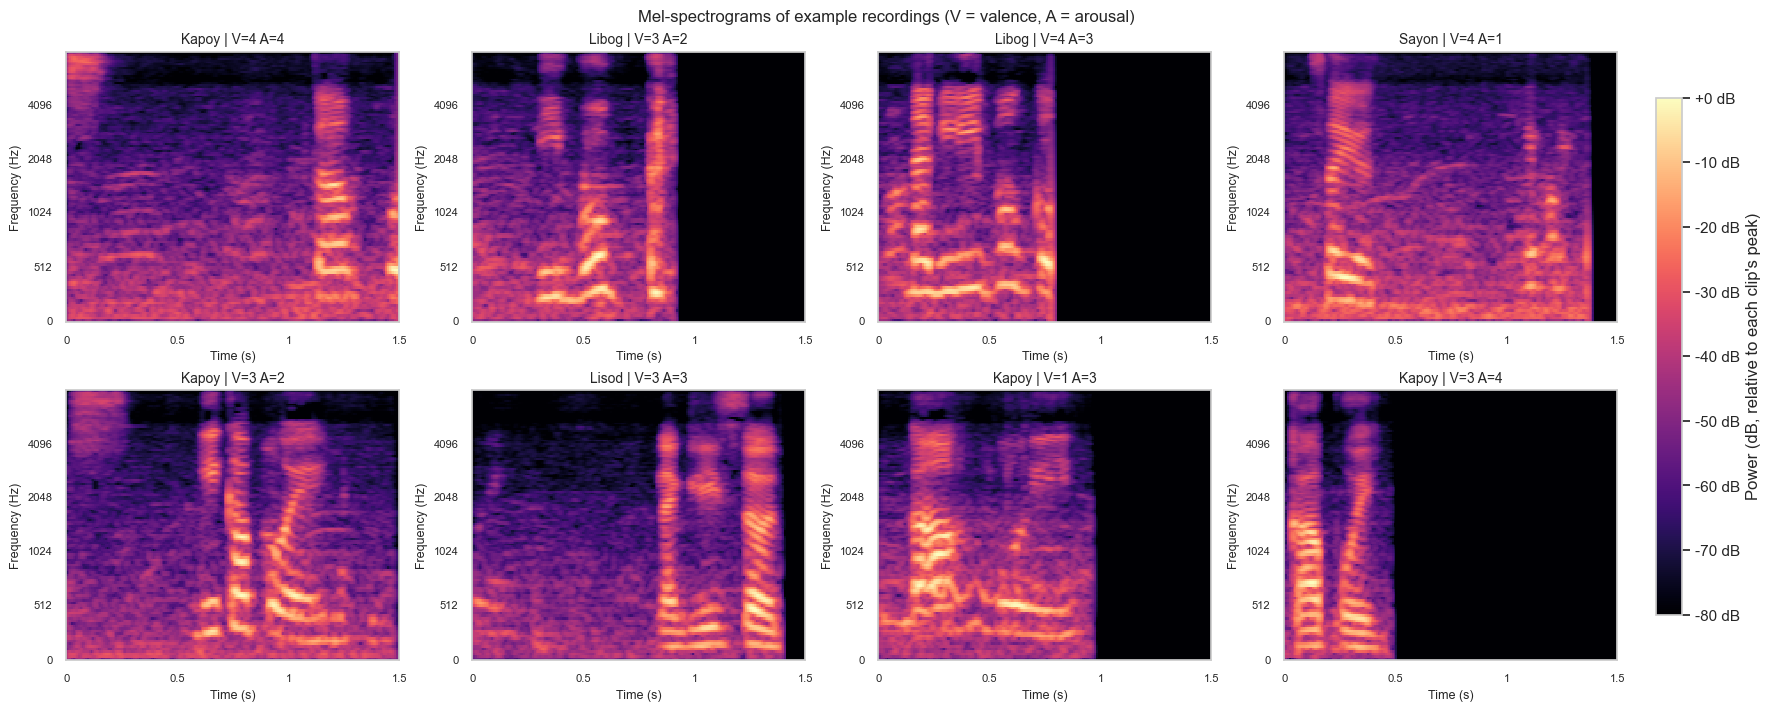

saved 30 labelled spectrograms to: RESULTSV3\spectrograms_labelled


In [13]:
# ---------------- labelled spectrogram summary figure (report Figure 1) ----------------
N_SHOW = 8          # how many recordings to show
SHOW_WORD = None    # e.g. "Kapoy" to show only that word, sorted by valence (same-word comparison); None = first N_SHOW

show_idx = df.index.tolist()
if SHOW_WORD:
    show_idx = df[df["word"] == SHOW_WORD].sort_values("valence").index.tolist()
show_idx = show_idx[:N_SHOW]

if not show_idx:
    print(f"No recordings found for SHOW_WORD = {SHOW_WORD!r}")
else:
    ncols = 4
    nrows = math.ceil(len(show_idx) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.4 * ncols, 3.5 * nrows), squeeze=False, constrained_layout=True)
    for ax in axes.ravel():
        ax.set_visible(False)
    img = None
    for ax, i in zip(axes.ravel(), show_idx):
        ax.set_visible(True)
        r = df.loc[i]
        img = draw_labelled(ax, audio_cache[i], f"{r['word']} | V={r['valence']} A={r['arousal']}")
    fig.colorbar(img, ax=axes.ravel().tolist(), shrink=0.85, pad=0.02,
                 label="Power (dB, relative to each clip's peak)", format="%+.0f dB")
    fig.suptitle("Mel-spectrograms of example recordings (V = valence, A = arousal)", fontsize=12)
    save_fig(fig, f"spectrogram_examples_{SHOW_WORD.lower()}" if SHOW_WORD else "spectrogram_examples")
    plt.show()

# ---------------- one labelled spectrogram per recording ----------------
for i, r in df.iterrows():
    fig, ax = plt.subplots(figsize=(6.5, 4.2), constrained_layout=True)
    img = draw_labelled(ax, audio_cache[i], f"{r['word']} | V={r['valence']} A={r['arousal']}\n{Path(r['file']).stem}")
    fig.colorbar(img, ax=ax, label="Power (dB, relative to clip's peak)", format="%+.0f dB")
    fig.savefig(LABELLED_DIR / f"{Path(r['file']).stem}.png", dpi=200, bbox_inches="tight")
    plt.close(fig)   # close so 30+ figures are not kept in memory or displayed
print(f"saved {len(df)} labelled spectrograms to: {LABELLED_DIR}")

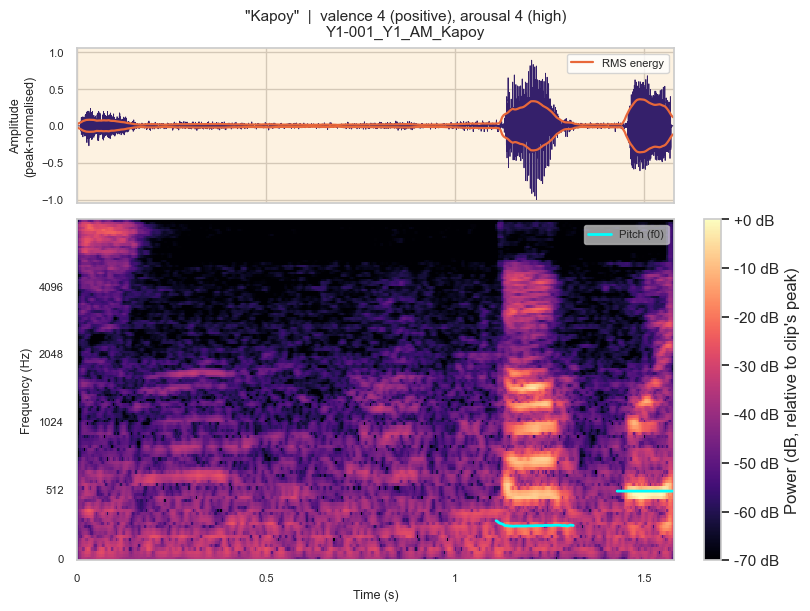

saved 30 waveform + spectrogram figures to: RESULTSV3\waveforms_spectrograms
saved: RESULTSV3\word_gallery_grabe.png
saved: RESULTSV3\word_gallery_kapoy.png
saved: RESULTSV3\word_gallery_libog.png
saved: RESULTSV3\word_gallery_lingaw.png
saved: RESULTSV3\word_gallery_lisod.png
saved: RESULTSV3\word_gallery_salamat.png
saved: RESULTSV3\word_gallery_sayon.png


In [14]:
VIZ_DIR = OUT_DIR / "waveforms_spectrograms"
VIZ_DIR.mkdir(parents=True, exist_ok=True)

VIZ_NFFT = 512       # 32 ms window
VIZ_HOP = 64         # 4 ms step
VIZ_FMAX = 8000      # Hz shown on the spectrogram
VIZ_DB_FLOOR = -70   # dB below each clip's peak shown as black


def viz_spectrogram(y):
    S = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=VIZ_NFFT, hop_length=VIZ_HOP, n_mels=128, fmax=VIZ_FMAX)
    return librosa.power_to_db(S, ref=np.max)


def viz_pitch(y):
    f0, _, _ = librosa.pyin(y, fmin=65, fmax=500, sr=SR, frame_length=1024, hop_length=VIZ_HOP)
    t = librosa.times_like(f0, sr=SR, hop_length=VIZ_HOP)
    return t, f0


def draw_waveform(ax, y, show_xlabel=True):
    t = np.arange(len(y)) / SR
    ax.plot(t, y, color="#35206B", linewidth=0.6)
    rms = librosa.feature.rms(y=y, frame_length=512, hop_length=VIZ_HOP)[0]
    t_rms = librosa.times_like(rms, sr=SR, hop_length=VIZ_HOP)
    ax.plot(t_rms, rms, color="#E8683A", linewidth=1.6, label="RMS energy")
    ax.plot(t_rms, -rms, color="#E8683A", linewidth=1.6)
    for s, e in librosa.effects.split(y, top_db=30):          # shade the detected speech segments
        ax.axvspan(s / SR, e / SR, color="#F9B95C", alpha=0.18, linewidth=0)
    ax.set_xlim(0, len(y) / SR)
    ax.set_ylim(-1.05, 1.05)
    ax.set_ylabel("Amplitude\n(peak-normalised)", fontsize=9)
    if show_xlabel:
        ax.set_xlabel("Time (s)", fontsize=9)
    ax.tick_params(labelsize=8)


def draw_clear_spectrogram(ax, y, show_xlabel=True, pitch=True):
    img = librosa.display.specshow(viz_spectrogram(y), sr=SR, hop_length=VIZ_HOP, x_axis="time", y_axis="mel",
                                   fmax=VIZ_FMAX, cmap="magma", vmin=VIZ_DB_FLOOR, vmax=0, ax=ax)
    if pitch:
        t, f0 = viz_pitch(y)
        ax.plot(t, f0, color="cyan", linewidth=2, label="Pitch (f0)")
        ax.legend(loc="upper right", fontsize=8, framealpha=0.6)
    ax.grid(False)
    ax.set_xlim(0, len(y) / SR)
    ax.set_ylabel("Frequency (Hz)", fontsize=9)
    ax.set_xlabel("Time (s)" if show_xlabel else "", fontsize=9)
    ax.tick_params(labelsize=8)
    return img


# ---------------- 1. one figure per recording ----------------
for k, (i, r) in enumerate(df.iterrows()):
    y = audio_cache[i]
    fig, (ax_w, ax_s) = plt.subplots(2, 1, figsize=(8, 6), sharex=True,
                                     gridspec_kw={"height_ratios": [1, 2.2]}, constrained_layout=True)
    draw_waveform(ax_w, y, show_xlabel=False)
    ax_w.legend(loc="upper right", fontsize=8)
    img = draw_clear_spectrogram(ax_s, y)
    fig.colorbar(img, ax=ax_s, format="%+.0f dB", label="Power (dB, relative to clip's peak)")
    fig.suptitle(f"\"{r['word']}\"  |  valence {r['valence']} ({r['valence_class']}), "
                 f"arousal {r['arousal']} ({r['arousal_class']})\n{Path(r['file']).stem}", fontsize=11)
    fig.savefig(VIZ_DIR / f"{Path(r['file']).stem}.png", dpi=200, bbox_inches="tight")
    if k == 0:
        plt.show()          # show the first one as an example
    else:
        plt.close(fig)      # close the rest so 30 figures are not displayed
print(f"saved {len(df)} waveform + spectrogram figures to: {VIZ_DIR}")

# ---------------- 2. one gallery per word (same-word comparison) ----------------
for word, g in df.groupby("word"):
    g = g.sort_values(["valence", "arousal"])
    n = len(g)
    t_max = max(len(audio_cache[i]) for i in g.index) / SR     # same time axis for every row
    fig, axes = plt.subplots(n, 2, figsize=(13, 2.1 * n + 0.8), squeeze=False,
                             gridspec_kw={"width_ratios": [1, 1.25]}, constrained_layout=True)
    img = None
    for row, (i, r) in enumerate(g.iterrows()):
        last = row == n - 1
        draw_waveform(axes[row, 0], audio_cache[i], show_xlabel=last)
        img = draw_clear_spectrogram(axes[row, 1], audio_cache[i], show_xlabel=last, pitch=True)
        for ax in axes[row]:
            ax.set_xlim(0, t_max)
        axes[row, 1].get_legend().remove()
        axes[row, 0].set_title(f"{r['participant']}  |  V={r['valence']}  A={r['arousal']}", fontsize=9, loc="left")
    fig.colorbar(img, ax=axes[:, 1].tolist(), format="%+.0f dB", shrink=0.6, label="dB re. clip peak")
    fig.suptitle(f"\"{word}\" – {n} recording(s), sorted by valence (cyan line = pitch, shaded = speech)", fontsize=12)
    out = OUT_DIR / f"word_gallery_{word.lower()}.png"
    fig.savefig(out, dpi=200, bbox_inches="tight")
    plt.close(fig)
    print("saved:", out)

### RQ3: acoustic characteristics by self-reported affect (descriptive)
Mean and standard deviation of key acoustic features per self-reported class, with boxplots. p-values are Mann-Whitney tests, **uncorrected and exploratory** (many comparisons, small n); do not claim significance from them. Audio is peak-normalised, so RMS reflects loudness relative to each clip's peak, not absolute loudness.


=== valence_class (n per class: {'non-positive': 18, 'positive': 12}) ===


,feature,non-positive median,positive median,non-positive mean (sd),positive mean (sd),p (uncorrected)
0,f0_mean,204.119,200.664,205.807 (55.592),204.942 (69.136),0.816
1,f0_std,19.398,23.476,36.959 (35.615),35.531 (35.732),0.949
2,rms_mean,0.114,0.095,0.122 (0.034),0.101 (0.030),0.072
3,zcr_mean,0.091,0.090,0.105 (0.048),0.103 (0.037),0.849
4,duration,0.800,0.944,0.844 (0.299),1.088 (0.452),0.156
5,active_ratio,1.000,1.000,0.980 (0.076),0.977 (0.068),0.694


saved: RESULTSV2\rq3_valence_class_acoustic_boxplots.png


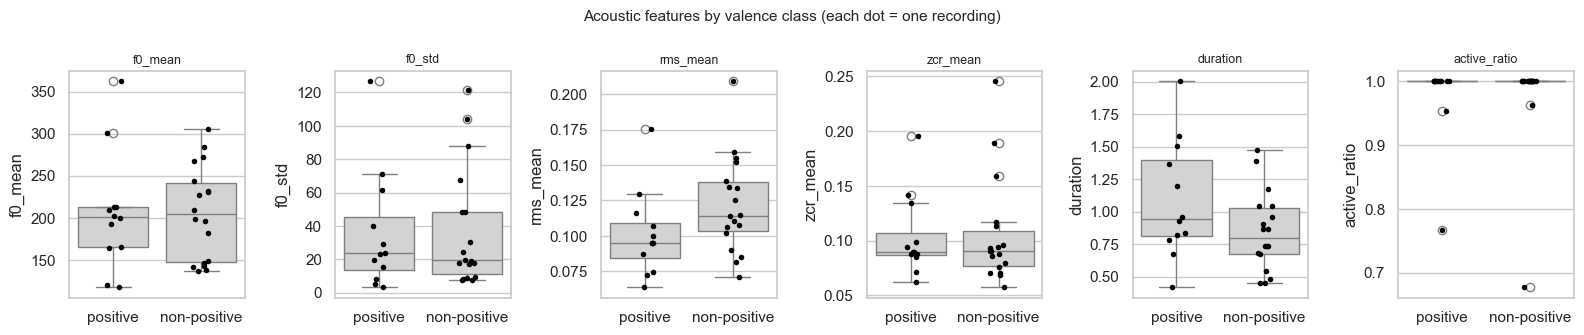


=== arousal_class (n per class: {'low-mod': 20, 'high': 10}) ===


,feature,high median,low-mod median,high mean (sd),low-mod mean (sd),p (uncorrected)
0,f0_mean,204.634,200.361,214.867 (77.340),200.757 (51.279),0.775
1,f0_std,26.301,19.398,43.948 (43.391),32.607 (30.625),0.676
2,rms_mean,0.101,0.112,0.114 (0.044),0.113 (0.028),0.582
3,zcr_mean,0.093,0.090,0.107 (0.040),0.102 (0.045),0.644
4,duration,0.880,0.864,0.997 (0.491),0.914 (0.323),0.809
5,active_ratio,1.000,1.000,1.000 (0.000),0.968 (0.086),0.147


saved: RESULTSV2\rq3_arousal_class_acoustic_boxplots.png


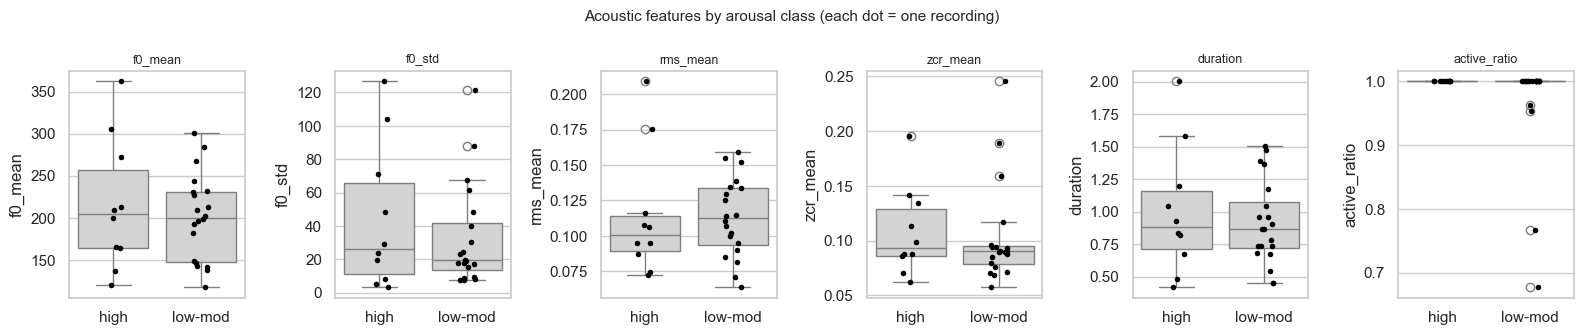

In [11]:
KEY_AUDIO = ["f0_mean", "f0_std", "rms_mean", "zcr_mean", "duration", "active_ratio"]

for target in ["valence_class", "arousal_class"]:
    d = hand[KEY_AUDIO].copy()
    d[target] = df[target].values
    classes = sorted(d[target].unique())
    rows = []
    for fcol in KEY_AUDIO:
        a, b = [d.loc[d[target] == k, fcol].values for k in classes[:2]]
        p = mannwhitneyu(a, b).pvalue if len(a) > 1 and len(b) > 1 else np.nan
        rows.append({"feature": fcol,
                     **{f"{k} median": round(d.loc[d[target] == k, fcol].median(), 3) for k in classes},
                     **{f"{k} mean (sd)": f"{d.loc[d[target] == k, fcol].mean():.3f} ({d.loc[d[target] == k, fcol].std():.3f})"
                        for k in classes},
                     "p (uncorrected)": round(p, 3)})
    tbl = pd.DataFrame(rows)
    print(f"\n=== {target} (n per class: {d[target].value_counts().to_dict()}) ===")
    display(tbl)
    tbl.to_csv(OUT_DIR / f"rq3_{target}_acoustic_comparison.csv", index=False, encoding="utf-8")

    fig, axes = plt.subplots(1, len(KEY_AUDIO), figsize=(16, 3.4))
    for ax, fcol in zip(axes, KEY_AUDIO):
        sns.boxplot(data=d, x=target, y=fcol, ax=ax, color="lightgray")
        sns.stripplot(data=d, x=target, y=fcol, ax=ax, color="black", size=4)
        ax.set_xlabel(""); ax.set_title(fcol, fontsize=9)
    fig.suptitle(f"Acoustic features by {target.replace('_', ' ')} (each dot = one recording)", fontsize=11)
    plt.tight_layout()
    save_fig(fig, f"rq3_{target}_acoustic_boxplots")
    plt.show()

In [12]:
# Descriptive statistics for every audio feature, overall and by self-reported class.
# Uses the real features (hand) and labels (df) computed above.
KEY = ["duration", "f0_mean", "f0_std", "f0_range", "voiced_ratio", "rms_mean", "rms_max",
       "zcr_mean", "centroid_mean", "n_segments", "active_ratio", "rms_peak_pos"]

audio_desc = hand.describe().T.round(3)
display(audio_desc)
audio_desc.to_csv(OUT_DIR / "audio_descriptive_statistics.csv", encoding="utf-8")

for target in ["valence_class", "arousal_class"]:
    t = hand[KEY].groupby(df[target].values).agg(["mean", "std"]).round(3).T
    print(f"\n--- Statistics by {target} ---")
    display(t)
    t.to_csv(OUT_DIR / f"audio_descriptive_by_{target}.csv", encoding="utf-8")

,count,mean,std,min,25%,50%,75%,max
duration,30.0,0.942,0.380,0.416,0.696,0.864,1.141,2.005
n_segments,30.0,1.167,0.461,1.000,1.000,1.000,1.000,3.000
active_ratio,30.0,0.979,0.072,0.677,1.000,1.000,1.000,1.000
rms_peak_pos,30.0,0.406,0.214,0.095,0.238,0.352,0.538,0.959
f0_mean,30.0,205.461,60.207,117.408,152.208,200.664,231.347,362.457
...,...,...,...,...,...,...,...,...
ddmfcc11_std,30.0,3.154,0.723,1.560,2.580,3.146,3.752,4.558
mfcc12_mean,30.0,0.427,6.339,-17.461,-3.395,1.263,4.774,9.110
mfcc12_std,30.0,8.668,2.763,4.357,6.516,8.125,10.400,15.450
dmfcc12_std,30.0,3.186,1.009,1.497,2.382,3.129,3.826,5.104



--- Statistics by valence_class ---


non-positive  positive
duration      mean         0.844     1.088
              std          0.299     0.452
f0_mean       mean       205.807   204.942
              std         55.592    69.136
f0_std        mean        36.959    35.531
              std         35.615    35.732
f0_range      mean       113.469   103.188
              std        104.605    82.221
voiced_ratio  mean         0.829     0.641
              std          0.157     0.260
rms_mean      mean         0.122     0.101
              std          0.034     0.030
rms_max       mean         0.298     0.286
              std          0.058     0.048
zcr_mean      mean         0.105     0.103
              std          0.048     0.037
centroid_mean mean      1410.778  1443.281
              std        348.911   318.439
n_segments    mean         1.167     1.167
              std          0.514     0.389
active_ratio  mean         0.980     0.977
              std          0.076     0.068
rms_peak_pos  mean         0.383     0.441
              std          0.207     0.228


--- Statistics by arousal_class ---


high   low-mod
duration      mean     0.997     0.914
              std      0.491     0.323
f0_mean       mean   214.867   200.757
              std     77.340    51.279
f0_std        mean    43.948    32.607
              std     43.391    30.625
f0_range      mean   125.078   101.496
              std    107.911    89.628
voiced_ratio  mean     0.686     0.787
              std      0.278     0.186
rms_mean      mean     0.114     0.113
              std      0.044     0.028
rms_max       mean     0.302     0.289
              std      0.064     0.048
zcr_mean      mean     0.107     0.102
              std      0.040     0.045
centroid_mean mean  1507.240  1382.049
              std    326.655   334.647
n_segments    mean     1.000     1.250
              std      0.000     0.550
active_ratio  mean     1.000     0.968
              std      0.000     0.086
rms_peak_pos  mean     0.453     0.382
              std      0.220     0.213

### Spectrogram embeddings (frozen pretrained ResNet18)
The ImageNet ResNet18 is used only as a fixed feature extractor (512 values per image); it is not trained on this data.

In [18]:
net = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
net.fc = torch.nn.Identity()
net.eval()
tf = T.Compose([T.ToTensor(), T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])])
with torch.no_grad():
    X_cnn = np.vstack([net(tf(Image.open(p).convert("RGB")).unsqueeze(0)).squeeze(0).numpy() for p in img_paths])
print("Spectrogram CNN embeddings:", X_cnn.shape)
np.save(OUT_DIR / "cnn_embeddings.npy", X_cnn)

Spectrogram CNN embeddings: (30, 512)


## 6. Export the audio dataset
One row per recording: metadata (context and labels, not predictors) followed by the audio features. A data dictionary lists every column and its group.

In [19]:
INCLUDE_CNN_EMBEDDINGS = False   # True adds the 512 spectrogram-embedding columns to the dataset


def from_meta(col):
    return df["file"].map(raw_idx[col]) if col in raw_idx.columns else pd.Series(np.nan, index=df.index)


meta = pd.DataFrame({
    "participant_code": df["participant"].values,
    "audio_filename": df["file"].values,
    "year_level": from_meta("Year Level").values,
    "class_activity": from_meta("Class Activity").values,
    "session": from_meta("Session").values,
    "spoken_word": df["word"].values,
    "self_reported_feeling": from_meta("Self-Reported Feeling").values,
    "valence": df["valence"].values,
    "arousal": df["arousal"].values,
    "valence_class": df["valence_class"].values,
    "arousal_class": df["arousal_class"].values,
})
audio_feats = hand.add_prefix("aud_").reset_index(drop=True)
parts_ = [meta, audio_feats]
if INCLUDE_CNN_EMBEDDINGS:
    parts_.append(pd.DataFrame(X_cnn, columns=[f"cnn_{i}" for i in range(X_cnn.shape[1])]))

assert len(meta) == len(audio_feats) == len(X_cnn), "row counts differ"
assert meta["audio_filename"].is_unique, "duplicate audio filenames"

audio_dataset = pd.concat(parts_, axis=1)
audio_dataset.to_csv(DATA_DIR / "Group1_audio_feature_dataset.csv", index=False, encoding="utf-8")

dd = [{"column": c, "group": "metadata (context and labels, NOT predictors)"} for c in meta.columns]
dd += [{"column": c, "group": "audio feature (handcrafted)"} for c in audio_feats.columns]
if INCLUDE_CNN_EMBEDDINGS:
    dd += [{"column": f"cnn_{i}", "group": "spectrogram CNN embedding"} for i in range(X_cnn.shape[1])]
pd.DataFrame(dd).to_csv(DATA_DIR / "data_dictionary.csv", index=False, encoding="utf-8")

print("Saved to", DATA_DIR)
print(f"Group1_audio_feature_dataset: {audio_dataset.shape[0]} rows x {audio_dataset.shape[1]} columns")
display(audio_dataset.iloc[:3, :14])

Saved to RESULTSV3\datasets
Group1_audio_feature_dataset: 30 rows x 78 columns


,participant_code,audio_filename,year_level,class_activity,session,spoken_word,self_reported_feeling,valence,arousal,valence_class,arousal_class,aud_duration,aud_n_segments,aud_active_ratio
0,Y1-001,Y1-001_Y1_AM_Kapoy.wav,1st Year,Examination,Morning,Kapoy,Kapoy,4,4,positive,high,1.578688,1,1.0
1,Y1-002,Y1-002_Y1_AM_Libog.wav,1st Year,Examination,Morning,Libog,Libog,3,2,non-positive,low-mod,0.906687,1,1.0
2,Y1-004,Y1-004_Y1_AM_Libog.wav,1st Year,Examination,Morning,Libog,Nagmahay ko kay wala nako nakita ang bonus,4,3,positive,low-mod,0.778687,1,1.0


## 7. Models (RQ4, RQ5)
- **Feature sets:** handcrafted acoustic features, and spectrogram-CNN embeddings.
- **Pipeline:** standardise -> PCA (5 components) -> classifier. Scaler and PCA are fitted **inside each training fold only**.
- **Models:** logistic regression, SVM (RBF), Random Forest, all with balanced class weights, against a majority-class baseline.
- **Evaluation:** leave-one-participant-out.

That is six audio configurations (2 feature sets x 3 models). Picking the best of six on the same data is optimistic.

In [20]:
FEATURE_SETS = {"Audio: handcrafted": X_hand, "Audio: spectrogram CNN": X_cnn}
MODELS = ["LogReg", "SVM", "RandomForest"]
TARGETS = ["valence_class", "arousal_class"]

groups = df["participant"].values
splits = list(LeaveOneGroupOut().split(X_hand, groups=groups))
print("Folds:", len(splits))


def make_model(kind):
    if kind == "LogReg":
        clf = LogisticRegression(C=0.5, max_iter=2000, class_weight="balanced")
    elif kind == "SVM":
        clf = SVC(kernel="rbf", C=1.0, class_weight="balanced")
    else:
        clf = RandomForestClassifier(n_estimators=100, max_depth=4, min_samples_leaf=2,
                                     class_weight="balanced", random_state=SEED)
    return make_pipeline(StandardScaler(), PCA(n_components=N_PCA, random_state=SEED), clf)


def predict_oof(cfg, y):
    if cfg["model"] == "Baseline":
        return cross_val_predict(DummyClassifier(strategy="most_frequent"), np.zeros((len(y), 1)), y, cv=splits)
    return cross_val_predict(make_model(cfg["model"]), FEATURE_SETS[cfg["features"]], y, cv=splits)


CONFIGS = [{"features": "Baseline (majority)", "model": "Baseline"}]
CONFIGS += [{"features": fs, "model": m} for fs in FEATURE_SETS for m in MODELS]

results, all_preds = {}, {}
for target in TARGETS:
    y = df[target].values
    rows = []
    for k, cfg in enumerate(CONFIGS):
        pred = predict_oof(cfg, y)
        all_preds[(target, k)] = pred
        rows.append({"features": cfg["features"], "model": cfg["model"],
                     "accuracy": round(accuracy_score(y, pred), 3),
                     "macro_f1": round(f1_score(y, pred, average="macro"), 3), "cfg_id": k})
    results[target] = pd.DataFrame(rows).sort_values("macro_f1", ascending=False).reset_index(drop=True)
    print(f"\n===== {target} =====")
    display(results[target].drop(columns="cfg_id"))

pd.concat([r.assign(target=t) for t, r in results.items()]).drop(columns="cfg_id").to_csv(
    OUT_DIR / "model_results.csv", index=False)

Folds: 30

===== valence_class =====


,features,model,accuracy,macro_f1
0,Audio: handcrafted,LogReg,0.733,0.722
1,Audio: handcrafted,SVM,0.700,0.683
2,Audio: spectrogram CNN,LogReg,0.633,0.612
3,Audio: spectrogram CNN,SVM,0.533,0.514
4,Audio: handcrafted,RandomForest,0.500,0.486
5,Audio: spectrogram CNN,RandomForest,0.433,0.377
6,Baseline (majority),Baseline,0.600,0.375



===== arousal_class =====


,features,model,accuracy,macro_f1
0,Audio: spectrogram CNN,LogReg,0.600,0.550
1,Audio: handcrafted,SVM,0.533,0.475
2,Audio: handcrafted,LogReg,0.500,0.471
3,Audio: spectrogram CNN,RandomForest,0.567,0.466
4,Baseline (majority),Baseline,0.667,0.400
5,Audio: spectrogram CNN,SVM,0.467,0.400
6,Audio: handcrafted,RandomForest,0.433,0.345


### Confusion matrices, per-class metrics, and per-recording predictions
Best audio configuration per target (highest macro-F1). Top: valence. Bottom: arousal. The predictions CSV lists every recording with its word and whether it was classified correctly, for the error analysis.


--- valence_class | Audio: handcrafted (LogReg) ---
              precision    recall  f1-score   support

non-positive       0.78      0.78      0.78        18
    positive       0.67      0.67      0.67        12

    accuracy                           0.73        30
   macro avg       0.72      0.72      0.72        30
weighted avg       0.73      0.73      0.73        30


--- arousal_class | Audio: spectrogram CNN (LogReg) ---
              precision    recall  f1-score   support

        high       0.40      0.40      0.40        10
     low-mod       0.70      0.70      0.70        20

    accuracy                           0.60        30
   macro avg       0.55      0.55      0.55        30
weighted avg       0.60      0.60      0.60        30

saved: RESULTSV3\confusion_matrices.png


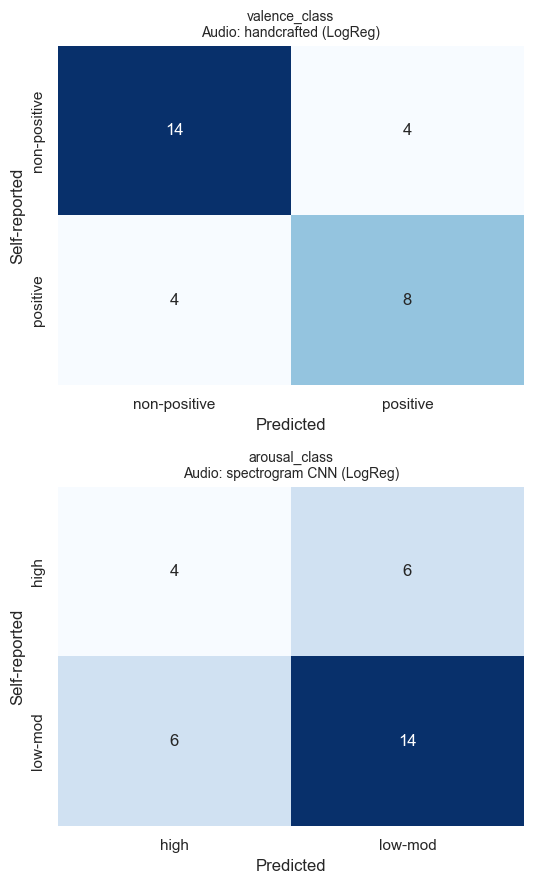

Errors by spoken word (best model):


target,arousal_class,valence_class
word,,
Grabe,2,0
Kapoy,5,3
Libog,1,1
Lingaw,2,2
Lisod,0,1
Salamat,1,1
Sayon,1,0


In [21]:
def best_of(target):
    res = results[target]
    return res[res["model"] != "Baseline"].iloc[0]


fig, axes = plt.subplots(2, 1, figsize=(5.5, 9))
best_cfg, pred_rows = {}, []
for ax, target in zip(axes, TARGETS):
    y = df[target].values
    labels = sorted(set(y))
    best = best_of(target)
    k = int(best["cfg_id"])
    best_cfg[target] = CONFIGS[k]
    pred = all_preds[(target, k)]
    cm = confusion_matrix(y, pred, labels=labels)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels, ax=ax, cbar=False)
    ax.set_title(f"{target}\n{best['features']} ({best['model']})", fontsize=10)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Self-reported")
    print(f"\n--- {target} | {best['features']} ({best['model']}) ---")
    print(classification_report(y, pred, zero_division=0))
    for i in range(len(y)):
        pred_rows.append({"target": target, "file": df.loc[i, "file"], "word": df.loc[i, "word"],
                          "self_reported": y[i], "predicted": pred[i], "correct": y[i] == pred[i]})
plt.tight_layout()
save_fig(fig, "confusion_matrices")
plt.show()

preds_df = pd.DataFrame(pred_rows)
preds_df.to_csv(OUT_DIR / "best_model_predictions.csv", index=False, encoding="utf-8")
print("Errors by spoken word (best model):")
display(preds_df.assign(error=~preds_df["correct"]).pivot_table(index="word", columns="target",
                                                                values="error", aggfunc="sum").fillna(0).astype(int))

### Accuracy: 95% Wilson interval and binomial test against the majority baseline
If the baseline accuracy lies inside the interval, the model is not clearly better than always guessing the larger class.

In [22]:
sig_rows = []
for target in TARGETS:
    y = df[target].values
    best = best_of(target)
    pred = all_preds[(target, int(best["cfg_id"]))]
    n, k = len(y), int((pred == y).sum())
    base_acc = results[target].query("model == 'Baseline'").iloc[0]["accuracy"]
    bt = binomtest(k, n, p=base_acc, alternative="greater")                      # one-sided p-value
    ci = binomtest(k, n).proportion_ci(confidence_level=0.95, method="wilson")   # two-sided 95% interval
    sig_rows.append({"target": target, "best": f"{best['features']} ({best['model']})",
                     "correct": f"{k}/{n}", "accuracy": round(k / n, 3),
                     "wilson_95_low": round(ci.low, 3), "wilson_95_high": round(ci.high, 3),
                     "baseline_accuracy": base_acc, "baseline_inside_CI": ci.low <= base_acc <= ci.high,
                     "binomial_p_one_sided": round(bt.pvalue, 3)})
sig_df = pd.DataFrame(sig_rows)
sig_df.to_csv(OUT_DIR / "accuracy_significance.csv", index=False)
display(sig_df)

,target,best,correct,accuracy,wilson_95_low,wilson_95_high,baseline_accuracy,baseline_inside_CI,binomial_p_one_sided
0,valence_class,Audio: handcrafted (LogReg),22/30,0.733,0.556,0.858,0.600,True,0.094
1,arousal_class,Audio: spectrogram CNN (LogReg),18/30,0.600,0.423,0.754,0.667,True,0.835


## 8. Permutation test
Is the best configuration better than what shuffled labels would give? Each shuffle reruns the full leave-one-participant-out evaluation. The mean macro-F1 under shuffling is the correct chance reference (not the baseline macro-F1, which predicts one class). Choosing the best of six configurations first makes this test somewhat optimistic; state that in the limitations.

With `N_PERM = 1000` this cell takes a few minutes.

saved: RESULTSV3\permutation_valence_class.png


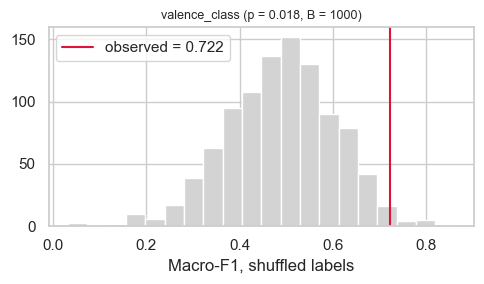

saved: RESULTSV3\permutation_arousal_class.png


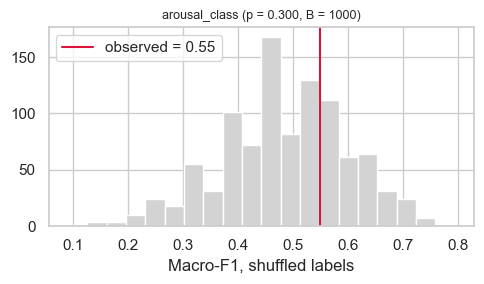

,target,best,observed_macro_f1,baseline_macro_f1,chance_mean,n_perm,p_value
0,valence_class,Audio: handcrafted (LogReg),0.722,0.375,0.490,1000,0.018
1,arousal_class,Audio: spectrogram CNN (LogReg),0.550,0.400,0.484,1000,0.300


In [23]:
rng = np.random.default_rng(SEED)
perm_summary = []
for target, cfg in best_cfg.items():
    y = df[target].values
    observed = best_of(target)["macro_f1"]
    base = results[target].query("model == 'Baseline'").iloc[0]["macro_f1"]
    null = np.array([f1_score(y_perm, predict_oof(cfg, y_perm), average="macro")
                     for y_perm in (rng.permutation(y) for _ in range(N_PERM))])
    p = (np.sum(null >= observed) + 1) / (N_PERM + 1)
    perm_summary.append({"target": target, "best": f"{cfg['features']} ({cfg['model']})",
                         "observed_macro_f1": observed, "baseline_macro_f1": base,
                         "chance_mean": round(null.mean(), 3), "n_perm": N_PERM, "p_value": round(p, 3)})
    fig = plt.figure(figsize=(5, 3))
    plt.hist(null, bins=20, color="lightgray")
    plt.axvline(observed, color="crimson", label=f"observed = {observed}")
    plt.title(f"{target} (p = {p:.3f}, B = {N_PERM})", fontsize=9)
    plt.xlabel("Macro-F1, shuffled labels"); plt.legend()
    plt.tight_layout()
    save_fig(fig, f"permutation_{target}")
    plt.show()
perm_df = pd.DataFrame(perm_summary)
perm_df.to_csv(OUT_DIR / "permutation_tests.csv", index=False)
perm_df

## 9. Lexically controlled analysis (descriptive)
Same spoken word, different self-reported affect. Only words that have recordings in both valence classes can be compared.

In [24]:
KEY_LEX = ["f0_mean", "f0_std", "rms_mean", "rms_max", "zcr_mean", "duration"]
lex = pd.concat([df[["word", "valence_class"]], hand[KEY_LEX]], axis=1)

counts = lex.groupby(["word", "valence_class"]).size().unstack(fill_value=0)
display(counts)
eligible = counts[(counts > 0).sum(axis=1) >= 2].index.tolist()
print("Words with both valence classes present:", eligible)
lex_desc = []
for w in eligible:
    print(f"\n--- {w} ---")
    t = lex[lex["word"] == w].groupby("valence_class").mean(numeric_only=True).round(3)
    display(t)
    lex_desc.append(t.assign(word=w).reset_index())
if lex_desc:
    pd.concat(lex_desc).to_csv(OUT_DIR / "lexically_controlled_descriptives.csv", index=False)

valence_class,non-positive,positive
word,,
Grabe,2,1
Kapoy,9,4
Libog,1,1
Lingaw,0,3
Lisod,3,0
Salamat,1,2
Sayon,2,1


Words with both valence classes present: ['Grabe', 'Kapoy', 'Libog', 'Salamat', 'Sayon']

--- Grabe ---


,f0_mean,f0_std,rms_mean,rms_max,zcr_mean,duration
valence_class,,,,,,
non-positive,185.141,7.387,0.118,0.282,0.092,0.656
positive,212.879,5.068,0.095,0.326,0.088,0.832



--- Kapoy ---


,f0_mean,f0_std,rms_mean,rms_max,zcr_mean,duration
valence_class,,,,,,
non-positive,203.267,42.147,0.115,0.278,0.085,0.900
positive,203.112,38.308,0.078,0.272,0.100,1.237


...

,f0_mean,f0_std,rms_mean,rms_max,zcr_mean,duration
valence_class,,,,,,
non-positive,267.546,30.382,0.134,0.349,0.079,0.907
positive,301.304,39.703,0.129,0.221,0.094,0.779



--- Salamat ---


,f0_mean,f0_std,rms_mean,rms_max,zcr_mean,duration
valence_class,,,,,,
non-positive,196.502,9.290,0.114,0.335,0.094,0.864
positive,204.634,24.342,0.102,0.269,0.165,1.467



--- Sayon ---


,f0_mean,f0_std,rms_mean,rms_max,zcr_mean,duration
valence_class,,,,,,
non-positive,226.378,61.05,0.145,0.327,0.151,0.608
positive,192.198,23.34,0.107,0.402,0.085,1.365


### Lexically controlled classification (Section XVII)
To hold the word constant statistically, each acoustic feature is centred **within each spoken word** (the word's mean is subtracted), so the model cannot use differences that only reflect which word was said. Then the same leave-one-participant-out evaluation is run. Words said by only one participant carry no information after centring. Exploratory only.

In [25]:
Xc = (hand - hand.groupby(df["word"].values).transform("mean")).values
lex_rows = []
for target in TARGETS:
    y = df[target].values
    pred = cross_val_predict(make_model("LogReg"), Xc, y, cv=splits)
    base_pred = cross_val_predict(DummyClassifier(strategy="most_frequent"), np.zeros((len(y), 1)), y, cv=splits)
    lex_rows.append({"target": target,
                     "uncentred handcrafted LogReg macro-F1": results[target].query(
                         "features == 'Audio: handcrafted' and model == 'LogReg'").iloc[0]["macro_f1"],
                     "word-centred macro-F1": round(f1_score(y, pred, average="macro"), 3),
                     "baseline macro-F1": round(f1_score(y, base_pred, average="macro"), 3),
                     "word-centred accuracy": round(accuracy_score(y, pred), 3),
                     "baseline accuracy": round(accuracy_score(y, base_pred), 3)})
lex_cls = pd.DataFrame(lex_rows)
lex_cls.to_csv(OUT_DIR / "lexically_controlled_results.csv", index=False)
lex_cls

,target,uncentred handcrafted LogReg macro-F1,word-centred macro-F1,baseline macro-F1,word-centred accuracy,baseline accuracy
0,valence_class,0.722,0.583,0.375,0.600,0.600
1,arousal_class,0.471,0.542,0.400,0.567,0.667


## Prototype recognition system (Section XX)
Takes one new WAV and returns the predicted valence and arousal class, using handcrafted features and logistic regression trained on all participants. It is a demonstration, not a validated model: its expected accuracy is the leave-one-participant-out result above, not performance on the training data.

In [26]:
final_models = {t: make_model("LogReg").fit(X_hand, df[t].values) for t in TARGETS}


def predict_affect(wav_path):
    feats = pd.DataFrame([handcrafted_features(load_audio(wav_path))])[hand.columns].fillna(0.0).values
    return {t: m.predict(feats)[0] for t, m in final_models.items()}


# Example (replace with a real file path):
example = AUDIO_DIR / "Y1-027_Y1_PM_Lingaw.wav"
if example.exists():
    print(example.name, "->", predict_affect(example))
else:
    print("Set `example` to a WAV file that exists.")

Y1-027_Y1_PM_Lingaw.wav -> {'valence_class': 'positive', 'arousal_class': 'high'}


## Interpretation checklist and limitations (deliverables 10 and 11)
**Interpretation**
- Does the best macro-F1 beat the permutation chance mean, and does the accuracy CI exclude the majority baseline? (RQ4)
- Which feature set and model scored highest, and is the gap larger than sampling noise? Call it "highest-scoring", not "best". (RQ5)
- Does the word-centred analysis still beat the baseline? If yes, how-it-is-spoken carries information beyond the word; if no, say so.
- Check `best_model_predictions.csv`: are errors concentrated in one word (e.g. Kapoy)?

**Limitations to state**
- Fewer than the required 40 observations (report the actual number and why; explain missing participant numbers).
- One year level only, so Year Level x Affect cannot be examined by this group.
- One recording per participant; binarised ratings; ratings are self-report.
- Best configuration chosen on the same data used for evaluation (optimistic).
- Peak-normalised audio, so absolute loudness is not preserved; recording distance and microphone differences are not controlled.
- Spoken words are unevenly distributed (and any off-protocol words are flagged), so word effects cannot be fully separated from affect.